# 1. Instalación e importación de bibliotecas




In [ ]:
# Instalar kagglehub para descargar el dataset
%pip install -q kagglehub

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import glob

# Preprocesamiento para modelado
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# Semilla y proporción de evaluación, fijadas para que los resultados se repitan
RANDOM_STATE = 42
TEST_SIZE = 0.20
np.random.seed(RANDOM_STATE)

# 2. Descarga y carga del dataset


In [ ]:
# Descargar dataset
path = kagglehub.dataset_download(
    "blastchar/telco-customer-churn"
)

# Buscar archivos CSV
archivos_csv = glob.glob(
    path + "/**/*.csv",
    recursive=True
)

# Comprobar que se haya encontrado un archivo CSV
if not archivos_csv:
    raise FileNotFoundError("No se encontraron archivos CSV")

print("Archivos encontrados:", archivos_csv)

# Definir la ruta del CSV una sola vez
DATA_PATH = archivos_csv[0]

# Cargar dataset con parámetros explícitos
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8", sep=",", decimal=".")

# Trabajar sobre una copia para conservar los datos originales
df = df_raw.copy()

print("Dataset cargado correctamente")

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Archivos encontrados: ['/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv']
Dataset cargado correctamente





> ### Problema de negocio

El objetivo es analizar el conjunto de datos de una empresa de telecomunicaciones para identificar características de sus clientes y detectar posibles patrones relacionados con la cancelación del servicio (Churn).

El análisis busca comprender qué características de los clientes, tipos de contrato y modalidades de pago pueden estar relacionadas con una mayor tasa de cancelación.

### Hipótesis

- Los clientes con menor antigüedad podrían presentar una mayor tasa de cancelación.
- Los clientes con contratos mensuales podrían cancelar con mayor frecuencia que aquellos con contratos de mayor duración.
- Los cargos mensuales podrían presentar diferencias entre los clientes que continúan y los que cancelan el servicio.
- La modalidad de pago podría estar relacionada con distintas tasas de cancelación.

### Variable objetivo

La variable objetivo es `Churn`, que indica si el cliente canceló el servicio (`Yes`) o continúa siendo cliente (`No`).

### Tipo de dataset

El conjunto de datos es estructurado, ya que presenta información organizada en filas y columnas. Cada fila representa un cliente y cada columna contiene una característica o variable.







# 3. Comprensión inicial del dataset

In [ ]:
# Mostrar las primeras filas
display(df.head())

# Mostrar dimensiones del dataset
print("DIMENSIONES DEL DATASET")
print(df.shape)

# Mostrar tipos de datos
print("\nTIPOS DE DATOS")
print(df.dtypes)

# Mostrar información general
print("\nINFORMACIÓN GENERAL")
df.info()

# Mostrar estadísticas descriptivas
print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


DIMENSIONES DEL DATASET
(7043, 21)

TIPOS DE DATOS
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# 4. Clasificación de las variables


In [ ]:
clasificacion = {
    "Identificador": [
        "customerID (identificador único del cliente)"
    ],

    "Cualitativas nominales (categorías sin orden)": [
        "gender (género)",
        "SeniorCitizen (adulto mayor: sí/no)",
        "Partner (tiene pareja: sí/no)",
        "Dependents (tiene dependientes: sí/no)",
        "PhoneService (servicio telefónico)",
        "MultipleLines (líneas telefónicas)",
        "InternetService (tipo de internet)",
        "OnlineSecurity (seguridad online)",
        "OnlineBackup (copia de seguridad)",
        "DeviceProtection (protección del dispositivo)",
        "TechSupport (soporte técnico)",
        "StreamingTV (televisión por streaming)",
        "StreamingMovies (películas por streaming)",
        "PaperlessBilling (facturación digital)",
        "PaymentMethod (método de pago)",
        "Churn (cancelación: sí/no)"
    ],

    "Cualitativas ordinales (categorías con orden)": [
        "Contract (duración del contrato)"
    ],

    "Cuantitativas discretas (valores enteros contables)": [
        "tenure (meses de antigüedad)"
    ],

    "Cuantitativas continuas (valores numéricos)": [
        "MonthlyCharges (cargo mensual)",
        "TotalCharges (cargos acumulados)"
    ]
}

# Mostrar clasificación de las variables
for tipo, variables in clasificacion.items():
    print(f"\n{tipo}:")
    for variable in variables:
        print("-", variable)

# Comparación entre la clasificación teórica y los tipos de datos de Pandas

comparacion = pd.DataFrame({
    "Variable": [
        "customerID",
        "gender",
        "SeniorCitizen",
        "Contract",
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Churn"
    ],
    "Clasificación teórica": [
        "Identificador",
        "Cualitativa nominal",
        "Cualitativa nominal",
        "Cualitativa ordinal",
        "Cuantitativa discreta",
        "Cuantitativa continua",
        "Cuantitativa continua",
        "Cualitativa nominal"
    ],
    "Tipo Pandas": [
        str(df["customerID"].dtype),
        str(df["gender"].dtype),
        str(df["SeniorCitizen"].dtype),
        str(df["Contract"].dtype),
        str(df["tenure"].dtype),
        str(df["MonthlyCharges"].dtype),
        str(df["TotalCharges"].dtype),
        str(df["Churn"].dtype)
    ]
})

display(comparacion)


Identificador:
- customerID (identificador único del cliente)

Cualitativas nominales (categorías sin orden):
- gender (género)
- SeniorCitizen (adulto mayor: sí/no)
- Partner (tiene pareja: sí/no)
- Dependents (tiene dependientes: sí/no)
- PhoneService (servicio telefónico)
- MultipleLines (líneas telefónicas)
- InternetService (tipo de internet)
- OnlineSecurity (seguridad online)
- OnlineBackup (copia de seguridad)
- DeviceProtection (protección del dispositivo)
- TechSupport (soporte técnico)
- StreamingTV (televisión por streaming)
- StreamingMovies (películas por streaming)
- PaperlessBilling (facturación digital)
- PaymentMethod (método de pago)
- Churn (cancelación: sí/no)

Cualitativas ordinales (categorías con orden):
- Contract (duración del contrato)

Cuantitativas discretas (valores enteros contables):
- tenure (meses de antigüedad)

Cuantitativas continuas (valores numéricos):
- MonthlyCharges (cargo mensual)
- TotalCharges (cargos acumulados)


,Variable,Clasificación teórica,Tipo Pandas
0,customerID,Identificador,object
1,gender,Cualitativa nominal,object
2,SeniorCitizen,Cualitativa nominal,int64
3,Contract,Cualitativa ordinal,object
4,tenure,Cuantitativa discreta,int64
5,MonthlyCharges,Cuantitativa continua,float64
6,TotalCharges,Cuantitativa continua,object
7,Churn,Cualitativa nominal,object


La clasificación teórica no siempre coincide con el tipo de dato que reconoce Pandas. Por ejemplo, `SeniorCitizen` representa una categoría, aunque esté almacenada como un número entero.

Además, `TotalCharges` inicialmente se encuentra almacenada como texto (`object`). Después de la limpieza y conversión, pasa a ser una variable numérica (`float64`).

# 5. Detección de problemas de calidad de datos

In [ ]:
# 1. Valores nulos
print("VALORES NULOS")
print(df.isnull().sum())

# 2. Cadenas vacías
print("\nCADENAS VACÍAS")

columnas_texto = df.select_dtypes(exclude="number").columns

print(
    df[columnas_texto]
    .apply(lambda col: col.str.strip().eq("").sum())
)

# 3. Filas duplicadas
print("\nFILAS DUPLICADAS")
print(df.duplicated().sum())

# 4. Identificadores repetidos
print("\nCUSTOMER ID REPETIDOS")
print(df["customerID"].duplicated().sum())

# 5. Categorías existentes
print("\nCATEGORÍAS")

for columna in columnas_texto.drop(["customerID", "TotalCharges"]):
    print(f"\n{columna}:")
    print(df[columna].unique())

# 6. Cargos mensuales negativos
print("\nCARGOS MENSUALES NEGATIVOS")
print((df["MonthlyCharges"] < 0).sum())

# 7. Valores de SeniorCitizen
print("\nSENIORCITIZEN")
print(df["SeniorCitizen"].value_counts())

VALORES NULOS
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

CADENAS VACÍAS
customerID           0
gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
Churn                0
dtype: int64

FILAS DUPLICADAS
0

CUSTOMER ID REPETIDOS
0

CATEGORÍAS

gender:
['

# 6. Tratamiento de valores faltantes y tipos de datos


In [ ]:
# Identificar registros con TotalCharges vacío
print("REGISTROS CON TOTALCHARGES VACÍO")

mascara_vacios = (
    df["TotalCharges"].astype("string").str.strip().eq("")
    | df["TotalCharges"].isnull()
)

display(
    df.loc[
        mascara_vacios,
        ["customerID", "tenure", "MonthlyCharges",
         "TotalCharges", "Churn"]
    ]
)

# Convertir TotalCharges a formato numérico
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Comprobar valores faltantes con tenure distinto de cero
print("NULOS CON TENURE DISTINTO DE CERO")

print(
    (
        df["TotalCharges"].isnull()
        & (df["tenure"] != 0)
    ).sum()
)

# Identificar valores faltantes con tenure = 0
mascara_cero = (
    df["TotalCharges"].isnull()
    & (df["tenure"] == 0)
)

# Reemplazar los valores faltantes por cero
df.loc[mascara_cero, "TotalCharges"] = 0

# Comprobar el tratamiento realizado
print("TRATAMIENTO DE TOTALCHARGES")
print("Tipo de dato:", df["TotalCharges"].dtype)
print("Valores nulos:", df["TotalCharges"].isnull().sum())

# Cargos acumulados negativos
print("CARGOS ACUMULADOS NEGATIVOS")
print((df["TotalCharges"] < 0).sum())

# Clientes sin antigüedad después del tratamiento
print("\nCLIENTES CON TENURE = 0")

display(
    df.loc[
        df["tenure"] == 0,
        ["customerID", "tenure", "TotalCharges", "Churn"]
    ]
)

# Información final del dataset
print("\nINFORMACIÓN FINAL")
df.info()

REGISTROS CON TOTALCHARGES VACÍO


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


NULOS CON TENURE DISTINTO DE CERO
0
TRATAMIENTO DE TOTALCHARGES
Tipo de dato: float64
Valores nulos: 0
CARGOS ACUMULADOS NEGATIVOS
0

CLIENTES CON TENURE = 0


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,0.0,No
753,3115-CZMZD,0,0.0,No
936,5709-LVOEQ,0,0.0,No
1082,4367-NUYAO,0,0.0,No
1340,1371-DWPAZ,0,0.0,No
3331,7644-OMVMY,0,0.0,No
3826,3213-VVOLG,0,0.0,No
4380,2520-SGTTA,0,0.0,No
5218,2923-ARZLG,0,0.0,No
6670,4075-WKNIU,0,0.0,No



INFORMACIÓN FINAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 

6.1. Filtrado de datos con múltiples condiciones

In [ ]:
# Clientes con más de 12 meses de antigüedad y cargos mensuales superiores a 70

filtro_1 = df[
    (df["tenure"] > 12) &
    (df["MonthlyCharges"] > 70)
]

display(filtro_1.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
12,8091-TTVAX,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,No,Credit card (automatic),100.35,5681.10,No
13,0280-XJGEX,Male,0,No,No,49,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes
14,5129-JLPIS,Male,0,No,No,25,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,105.50,2686.05,No


6.2. Filtrado utilizando OR

In [ ]:
# Clientes con contrato mensual o que cancelaron el servicio

filtro_2 = df[
    (df["Contract"] == "Month-to-month") |
    (df["Churn"] == "Yes")
]

display(filtro_2.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No


6.3. Agrupación con múltiples agregaciones

In [ ]:
# Resumen de clientes agrupados por tipo de contrato

resumen = df.groupby("Contract").agg(
    cantidad_clientes=("Churn", "count"),
    antiguedad_promedio=("tenure", "mean"),
    cargo_mensual_promedio=("MonthlyCharges", "mean"),
    cargos_acumulados_promedio=("TotalCharges", "mean"),
    cargos_acumulados_totales=("TotalCharges", "sum")
)

display(resumen)

,cantidad_clientes,antiguedad_promedio,cargo_mensual_promedio,cargos_acumulados_promedio,cargos_acumulados_totales
Contract,,,,,
Month-to-month,3875,18.036645,66.398490,1369.254581,5305861.5
One year,1473,42.044807,65.048608,3032.622878,4467053.5
Two year,1695,56.735103,60.770413,3706.934336,6283253.7


6.4. Creación de una columna calculada

In [ ]:
# Estimación simplificada de los cargos acumulados

df["CargosEstimados"] = (
    df["MonthlyCharges"] * df["tenure"]
)

display(
    df[[
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "CargosEstimados"
    ]].head()
)

,tenure,MonthlyCharges,TotalCharges,CargosEstimados
0,1,29.85,29.85,29.85
1,34,56.95,1889.50,1936.30
2,2,53.85,108.15,107.70
3,45,42.30,1840.75,1903.50
4,2,70.70,151.65,141.40


La columna `CargosEstimados` se obtiene multiplicando los cargos mensuales por la cantidad de meses de antigüedad.

Es una estimación simplificada que permite aplicar operaciones aritméticas sobre las variables. No representa necesariamente el importe real facturado, ya que los cargos mensuales pueden haber variado a lo largo del tiempo.

6.5. Renombrado de columnas

In [ ]:
# Ejemplo de renombrado sin modificar el DataFrame original

df_prueba = df.rename(
    columns={"customerID": "id_cliente"}
)

display(df_prueba.head())

,id_cliente,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CargosEstimados
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,29.85
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,1936.30
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,107.70
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,1903.50
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,141.40


6.6. Eliminación de una columna irrelevante para el análisis estadístico

In [ ]:
# Se elimina customerID de una copia, ya que es un identificador
# y no aporta información numérica útil para los cálculos estadísticos

df_sin_id = df.drop(columns=["customerID"])

display(df_sin_id.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CargosEstimados
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,1936.30
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,107.70
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,1903.50
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,141.40


La columna `customerID` funciona como identificador único del cliente. No aporta información numérica útil para los cálculos estadísticos, por lo que se excluye de una copia destinada al análisis.

Se conserva en el DataFrame original para poder identificar y rastrear los registros.

# 7. Análisis univariado

7.1. Análisis de variables numéricas

In [ ]:
# Estadísticas descriptivas de las variables numéricas
print("ESTADÍSTICAS NUMÉRICAS")
display(df.describe())

# Media, mediana y desvío estándar de MonthlyCharges
print("\nMONTHLYCHARGES")

print("Media:", df["MonthlyCharges"].mean())
print("Mediana:", df["MonthlyCharges"].median())
print("Desvío estándar:", df["MonthlyCharges"].std())

# Media, mediana y desvío estándar de tenure
print("\nTENURE")

print("Media:", df["tenure"].mean())
print("Mediana:", df["tenure"].median())
print("Desvío estándar:", df["tenure"].std())

# Media, mediana y desvío estándar de TotalCharges
print("\nTOTALCHARGES")

print("Media:", df["TotalCharges"].mean())
print("Mediana:", df["TotalCharges"].median())
print("Desvío estándar:", df["TotalCharges"].std())

ESTADÍSTICAS NUMÉRICAS


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,CargosEstimados
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,2279.581350
std,0.368612,24.559481,30.090047,2266.794470,2264.729447
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,394.000000
50%,0.000000,29.000000,70.350000,1394.550000,1393.600000
75%,0.000000,55.000000,89.850000,3786.600000,3786.100000
max,1.000000,72.000000,118.750000,8684.800000,8550.000000



MONTHLYCHARGES
Media: 64.76169246059918
Mediana: 70.35
Desvío estándar: 30.09004709767854

TENURE
Media: 32.37114865824223
Mediana: 29.0
Desvío estándar: 24.55948102309423

TOTALCHARGES
Media: 2279.7343035638223
Mediana: 1394.55
Desvío estándar: 2266.7944696890195


7.2. Análisis de variables categóricas

In [ ]:
# Frecuencia de Churn
print("DISTRIBUCIÓN DE CHURN")
print(df["Churn"].value_counts())

# Porcentajes de Churn
print("\nPORCENTAJES DE CHURN")

print(
    df["Churn"].value_counts(normalize=True) * 100
)

# Frecuencia de Contract
print("\nDISTRIBUCIÓN DE CONTRACT")
print(df["Contract"].value_counts())

# Porcentajes de Contract
print("\nPORCENTAJES DE CONTRACT")

print(
    df["Contract"].value_counts(normalize=True) * 100
)

# Frecuencias de variables sociodemográficas
variables = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

for columna in variables:
    print(f"\nDISTRIBUCIÓN DE {columna}")

    print("Frecuencias absolutas:")
    print(df[columna].value_counts())

    print("\nFrecuencias relativas (%):")
    print(df[columna].value_counts(normalize=True) * 100)

DISTRIBUCIÓN DE CHURN
Churn
No     5174
Yes    1869
Name: count, dtype: int64

PORCENTAJES DE CHURN
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

DISTRIBUCIÓN DE CONTRACT
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PORCENTAJES DE CONTRACT
Contract
Month-to-month    55.019168
Two year          24.066449
One year          20.914383
Name: proportion, dtype: float64

DISTRIBUCIÓN DE gender
Frecuencias absolutas:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Frecuencias relativas (%):
gender
Male      50.47565
Female    49.52435
Name: proportion, dtype: float64

DISTRIBUCIÓN DE SeniorCitizen
Frecuencias absolutas:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Frecuencias relativas (%):
SeniorCitizen
0    83.785319
1    16.214681
Name: proportion, dtype: float64

DISTRIBUCIÓN DE Partner
Frecuencias absolutas:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Frec

7.3. Visualización de variables individuales



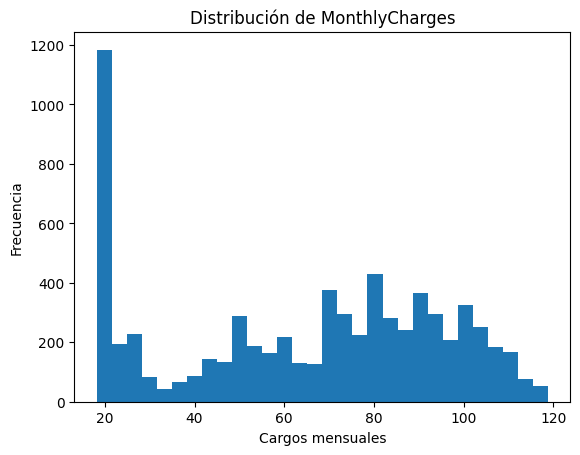

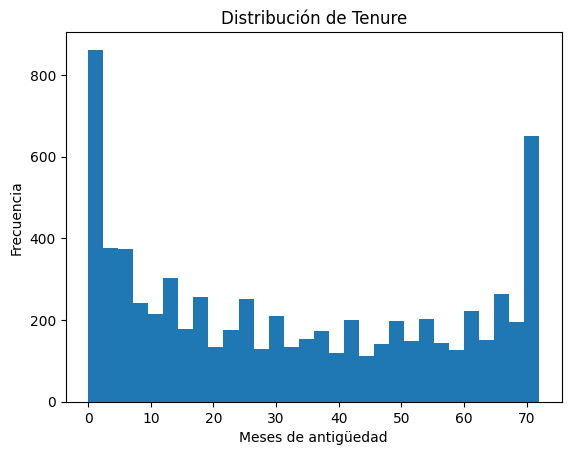

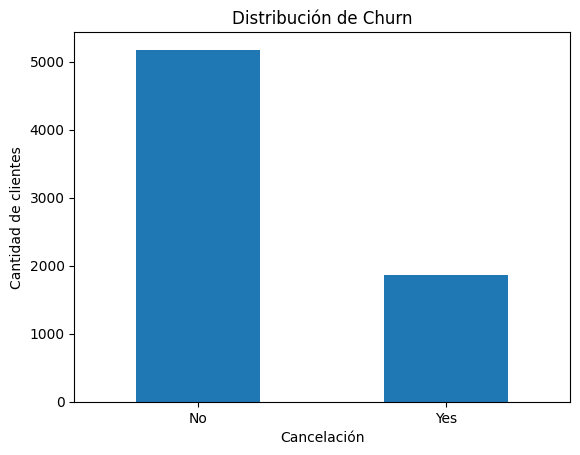

In [ ]:
# Histograma de MonthlyCharges
df["MonthlyCharges"].plot(
    kind="hist",
    bins=30,
    title="Distribución de MonthlyCharges"
)

plt.xlabel("Cargos mensuales")
plt.ylabel("Frecuencia")
plt.show()

# Histograma de tenure
df["tenure"].plot(
    kind="hist",
    bins=30,
    title="Distribución de Tenure"
)

plt.xlabel("Meses de antigüedad")
plt.ylabel("Frecuencia")
plt.show()

# Gráfico de barras de Churn
df["Churn"].value_counts().plot(
    kind="bar",
    title="Distribución de Churn"
)

plt.xlabel("Cancelación")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=0)
plt.show()

7.3.1. Histogramas con curva KDE

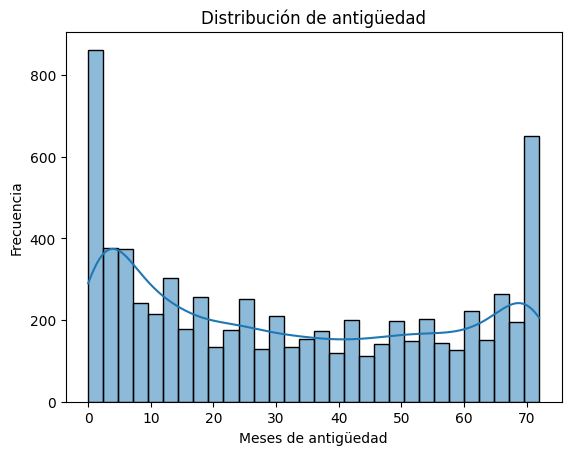

In [ ]:
# Histograma de tenure con curva KDE
sns.histplot(
    data=df,
    x="tenure",
    bins=30,
    kde=True
)

plt.title("Distribución de antigüedad")
plt.xlabel("Meses de antigüedad")
plt.ylabel("Frecuencia")
plt.show()

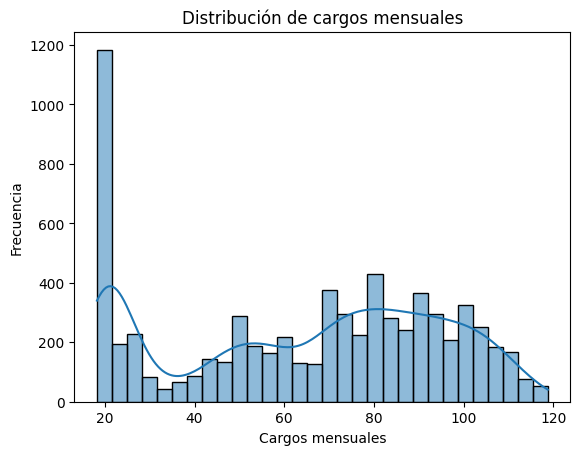

In [ ]:
# Histograma de MonthlyCharges con curva KDE
sns.histplot(
    data=df,
    x="MonthlyCharges",
    bins=30,
    kde=True
)

plt.title("Distribución de cargos mensuales")
plt.xlabel("Cargos mensuales")
plt.ylabel("Frecuencia")
plt.show()

### Interpretación de las visualizaciones univariadas

- **MonthlyCharges:** el histograma permite observar cuáles son los importes mensuales más frecuentes y cómo se distribuyen los cargos entre los clientes.
- **Tenure:** permite observar la antigüedad de los clientes y detectar en qué períodos se concentra la mayor cantidad de registros.
- **Churn:** el gráfico de barras permite comparar la cantidad de clientes que cancelaron el servicio con aquellos que continúan.
- **KDE:** la curva suavizada permite observar la forma general de la distribución de las variables numéricas.

# 8. Detección de valores atípicos (outliers)

8.1. Identificación de outliers mediante IQR




In [ ]:
# Calcular cuartiles e IQR
q1 = df["MonthlyCharges"].quantile(0.25)
q3 = df["MonthlyCharges"].quantile(0.75)

iqr = q3 - q1

# Calcular límites
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Identificar posibles outliers
outliers = df[
    (df["MonthlyCharges"] < limite_inferior) |
    (df["MonthlyCharges"] > limite_superior)
]

# Mostrar resultados
print("CANTIDAD DE OUTLIERS")
print(len(outliers))

print("\nREGISTROS IDENTIFICADOS")
display(outliers)

CANTIDAD DE OUTLIERS
0

REGISTROS IDENTIFICADOS


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CargosEstimados


8.2. Visualización de posibles outliers


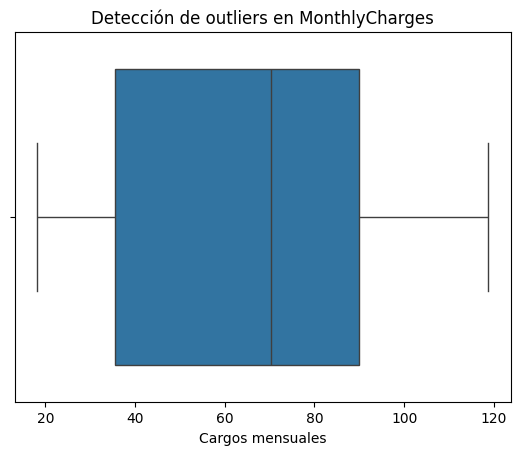

In [ ]:
# Diagrama de caja de MonthlyCharges
sns.boxplot(x=df["MonthlyCharges"])

plt.title("Detección de outliers en MonthlyCharges")
plt.xlabel("Cargos mensuales")
plt.show()

### Interpretación de valores atípicos

El método del rango intercuartílico (IQR) permite identificar posibles valores atípicos en `MonthlyCharges`.

Estos valores no necesariamente representan errores. Pueden corresponder a clientes que contrataron servicios adicionales o planes de mayor costo.

Por este motivo, se decide conservarlos en el conjunto de datos, ya que eliminarlos sin un análisis adicional podría provocar una pérdida de información relevante.

# 9. Análisis bivariado

9.1. Relación entre Churn y antigüedad

In [ ]:
print("ANTIGÜEDAD PROMEDIO SEGÚN CHURN")

display(
    df.groupby("Churn")["tenure"].mean()
)

ANTIGÜEDAD PROMEDIO SEGÚN CHURN


,tenure
Churn,
No,37.569965
Yes,17.979133


9.2. Relación entre Churn y cargos mensuales

In [ ]:
print("CARGOS MENSUALES SEGÚN CHURN")

display(
    df.groupby("Churn")["MonthlyCharges"].mean()
)

CARGOS MENSUALES SEGÚN CHURN


,MonthlyCharges
Churn,
No,61.265124
Yes,74.441332


9.3. Relación entre contrato y cancelación

In [ ]:
# Frecuencias absolutas
print("CONTRATO Y CANCELACIÓN")

display(
    pd.crosstab(
        df["Contract"],
        df["Churn"]
    )
)

# Porcentajes de cancelación dentro de cada contrato
print("\nPORCENTAJES SEGÚN TIPO DE CONTRATO")

display(
    pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    ) * 100
)

# Relación entre modalidad de pago y cancelación
print("\nMODALIDAD DE PAGO Y CANCELACIÓN")

display(
    pd.crosstab(
        df["PaymentMethod"],
        df["Churn"]
    )
)

# Porcentajes según modalidad de pago
print("\nPORCENTAJES SEGÚN MODALIDAD DE PAGO")

display(
    pd.crosstab(
        df["PaymentMethod"],
        df["Churn"],
        normalize="index"
    ) * 100
)

CONTRATO Y CANCELACIÓN


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48



PORCENTAJES SEGÚN TIPO DE CONTRATO


Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858



MODALIDAD DE PAGO Y CANCELACIÓN


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308



PORCENTAJES SEGÚN MODALIDAD DE PAGO


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


9.3.1. Relación entre variables sociodemográficas y cancelación

In [ ]:
# Relación entre variables sociodemográficas y Churn

variables = ["gender", "SeniorCitizen", "Partner", "Dependents"]

for columna in variables:
    print(f"\nCANCELACIÓN SEGÚN {columna}")

    display(
        pd.crosstab(
            df[columna],
            df["Churn"],
            normalize="index"
        ) * 100
    )


CANCELACIÓN SEGÚN gender


Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338



CANCELACIÓN SEGÚN SeniorCitizen


Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261



CANCELACIÓN SEGÚN Partner


Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903



CANCELACIÓN SEGÚN Dependents


Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


9.4. Visualización de la relación entre variables

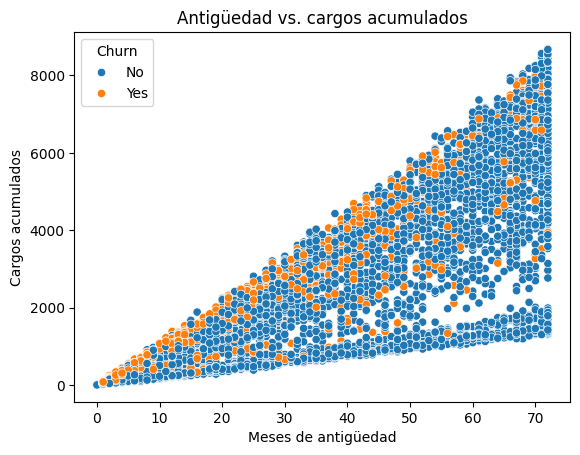

In [ ]:
# Gráfico de dispersión
sns.scatterplot(
    data=df,
    x="tenure",
    y="TotalCharges",
    hue="Churn"
)

plt.title("Antigüedad vs. cargos acumulados")
plt.xlabel("Meses de antigüedad")
plt.ylabel("Cargos acumulados")
plt.show()

9.4.1. Gráfico de cancelación según tipo de contrato

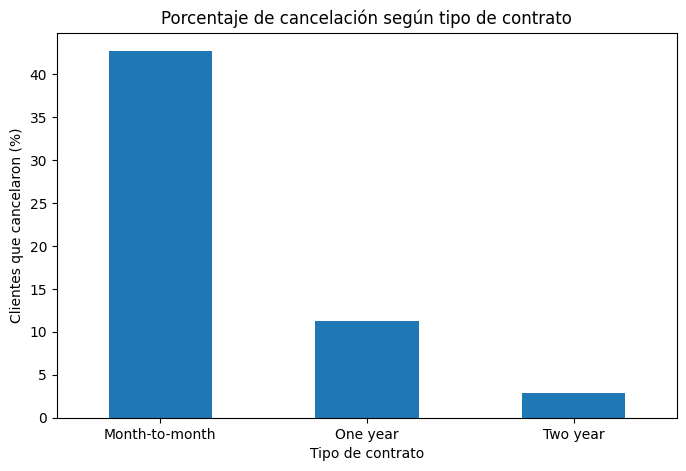

In [ ]:
# Porcentaje de cancelación según tipo de contrato

churn_contrato = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

churn_contrato["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Porcentaje de cancelación según tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Clientes que cancelaron (%)")
plt.xticks(rotation=0)
plt.show()

9.4.2. Gráfico de cancelación según modalidad de pago

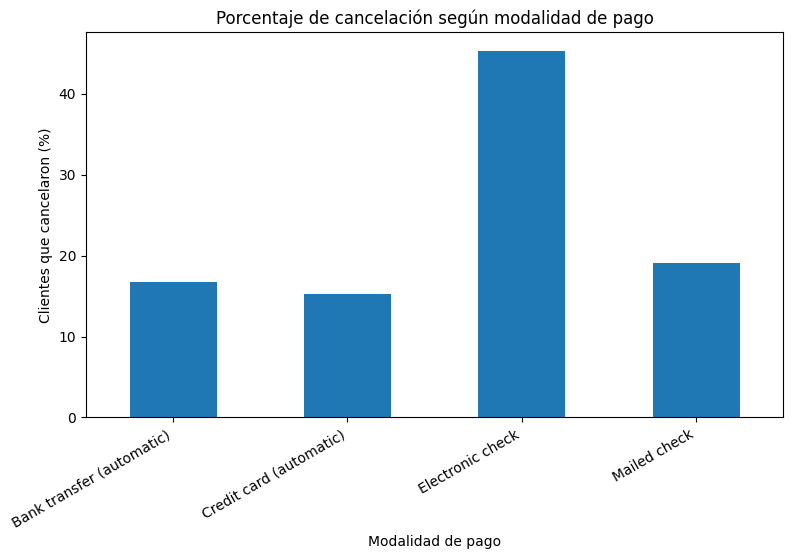

In [ ]:
# Porcentaje de cancelación según modalidad de pago

churn_pago = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

churn_pago["Yes"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Porcentaje de cancelación según modalidad de pago")
plt.xlabel("Modalidad de pago")
plt.ylabel("Clientes que cancelaron (%)")
plt.xticks(rotation=30, ha="right")
plt.show()

### Interpretación del análisis bivariado

- **Churn y antigüedad:** permite comparar la antigüedad promedio de los clientes que cancelaron y los que continúan. Una menor antigüedad promedio entre quienes cancelaron podría indicar una mayor concentración de cancelaciones durante los primeros meses.
- **Churn y cargos mensuales:** permite observar si existen diferencias en los cargos mensuales promedio entre ambos grupos de clientes.
- **Contrato y Churn:** permite comparar la proporción de cancelaciones según el tipo de contrato.
- **Modalidad de pago y Churn:** permite observar si las tasas de cancelación presentan diferencias según el método de pago.
- **Antigüedad y cargos acumulados:** el gráfico de dispersión permite observar la relación entre el tiempo de permanencia y los cargos acumulados, diferenciando a los clientes según su situación de cancelación.

Estos resultados permiten identificar asociaciones entre variables, pero no demuestran que una variable sea la causa directa de la cancelación.

# 10. Análisis multivariado

10.1. Relación entre contrato y variables numéricas

In [ ]:
print("PROMEDIOS SEGÚN TIPO DE CONTRATO")

display(
    df.groupby("Contract")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean()
)

PROMEDIOS SEGÚN TIPO DE CONTRATO


,tenure,MonthlyCharges,TotalCharges
Contract,,,
Month-to-month,18.036645,66.398490,1369.254581
One year,42.044807,65.048608,3032.622878
Two year,56.735103,60.770413,3706.934336


10.2. Relación entre contrato, cancelación y variables numéricas

In [ ]:
print("ANÁLISIS SEGÚN CONTRATO Y CHURN")

display(
    df.groupby(["Contract", "Churn"])[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean()
)

ANÁLISIS SEGÚN CONTRATO Y CHURN


tenure  MonthlyCharges  TotalCharges
Contract       Churn                                         
Month-to-month No     21.033333       61.462635   1521.927590
               Yes    14.016918       73.019396   1164.460574
One year       No     41.674063       62.508148   2901.348355
               Yes    44.963855       85.050904   4066.212048
Two year       No     56.602914       60.012477   3656.648604
               Yes    61.270833       86.777083   5432.363542

10.3. Matriz de correlación

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


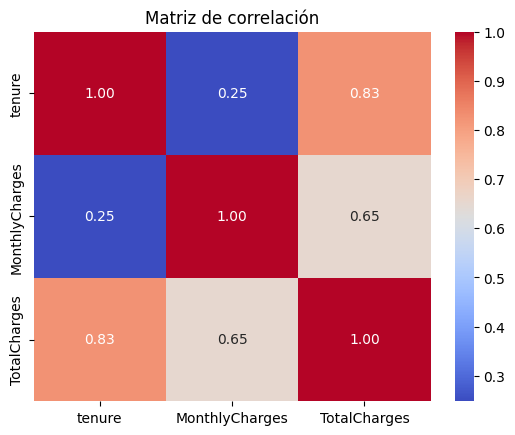

In [ ]:
# Calcular matriz de correlación
correlacion = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr()

# Mostrar matriz de correlación
display(correlacion)

# Visualizar matriz de correlación
sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación")
plt.show()

10.4. Correlación de Spearman

CORRELACIÓN DE SPEARMAN


,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.276417,0.889696
MonthlyCharges,0.276417,1.000000,0.638028
TotalCharges,0.889696,0.638028,1.000000


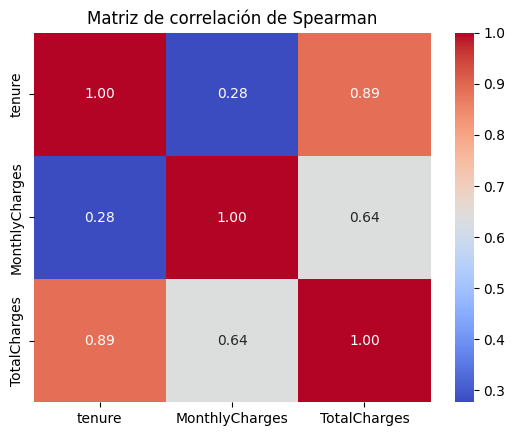

In [ ]:
# Calcular matriz de correlación utilizando Spearman
correlacion_spearman = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr(method="spearman")

# Mostrar matriz de correlación
print("CORRELACIÓN DE SPEARMAN")
display(correlacion_spearman)

# Visualizar matriz de correlación
sns.heatmap(
    correlacion_spearman,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación de Spearman")
plt.show()

### Comparación entre Pearson y Spearman

Pearson mide la intensidad y dirección de la relación lineal entre dos variables numéricas.

Spearman mide la relación monotónica entre las variables, utilizando sus posiciones relativas (rangos).

La comparación de ambas matrices permite observar si las relaciones entre las variables se mantienen o presentan diferencias según el método utilizado.

Los valores de correlación cercanos a 1 indican una relación positiva fuerte; los cercanos a -1 indican una relación negativa fuerte; y los cercanos a 0 indican una relación lineal o monotónica débil, según el método utilizado.

# 11. Preprocesamiento de datos para modelado

En esta sección se preparan los datos para entrenar, en la etapa siguiente, un modelo de **regresión lineal**. Como sugiere la consigna, la variable a estimar es `TotalCharges`, que es continua.

Pasos:

1. Separar las variables predictoras (`X`) de la variable objetivo (`y`).
2. Clasificar las variables según la técnica de preprocesamiento que necesita cada una.
3. Dividir los datos en entrenamiento y evaluación (80/20), con estratificación.
4. Codificar las variables categóricas (One-Hot y Ordinal) y estandarizar las numéricas.
5. Verificar el resultado.

**Orden de los pasos.** La consigna nombra primero la codificación y el escalado, y después la partición. En el código **se parte primero y se transforma después**: los codificadores y el escalador aprenden sus parámetros (categorías, medias y desvíos) solo con el conjunto de entrenamiento. Si aprendieran también del conjunto de evaluación, se produciría una **fuga de datos** (*data leakage*) y la evaluación del modelo resultaría demasiado optimista.

11.1. Separación de variables predictoras (X) y variable objetivo (y)

Se excluyen de `X` estas columnas:

- `customerID`: es un identificador y no aporta información para predecir.
- `CargosEstimados`: se calculó como `tenure × MonthlyCharges` y es casi una copia de `TotalCharges`. Si se usara como predictora, el modelo "vería" la respuesta, lo que es una forma de fuga de datos.
- `TotalCharges`: es la variable objetivo (`y`).

`Churn` se conserva como predictora porque es información disponible del cliente. Además, se usa para estratificar la partición.

In [ ]:
# Variable objetivo continua para la regresión
COLUMNA_OBJETIVO = "TotalCharges"

# Columnas que no se usan como predictoras
COLUMNAS_EXCLUIDAS = ["customerID", "CargosEstimados", COLUMNA_OBJETIVO]

X = df.drop(columns=COLUMNAS_EXCLUIDAS)
y = df[COLUMNA_OBJETIVO]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

11.2. Clasificación de las variables según su preprocesamiento

A partir de la clasificación de la sección 4, se elige una técnica para cada tipo de variable:

| Grupo | Variables | Técnica | Motivo |
| :---- | :---- | :---- | :---- |
| Cualitativas nominales | `gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `PaperlessBilling`, `PaymentMethod`, `Churn` | `OneHotEncoder` | Sus categorías no tienen orden. Asignarles números 0, 1, 2… inventaría un orden que no existe. |
| Cualitativa ordinal | `Contract` | `OrdinalEncoder` con el orden indicado a mano | Las categorías tienen un orden natural de duración: mensual < un año < dos años. |
| Cuantitativas | `tenure`, `MonthlyCharges` | `StandardScaler` | Tienen escalas distintas (0–72 meses y 18–119 de cargo mensual). |
| Nominal ya codificada | `SeniorCitizen` | Sin transformación (`passthrough`) | Ya está en formato 0/1. |

In [ ]:
# Grupos de columnas según el preprocesamiento que reciben
COLUMNAS_NOMINALES = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling",
    "PaymentMethod", "Churn"
]
COLUMNAS_ORDINALES = ["Contract"]
ORDEN_CONTRATO = ["Month-to-month", "One year", "Two year"]
COLUMNAS_NUMERICAS = ["tenure", "MonthlyCharges"]
COLUMNAS_SIN_TRANSFORMAR = ["SeniorCitizen"]

# Verificar que cada columna de X esté asignada exactamente a un grupo
columnas_asignadas = (
    COLUMNAS_NOMINALES + COLUMNAS_ORDINALES
    + COLUMNAS_NUMERICAS + COLUMNAS_SIN_TRANSFORMAR
)

print("Columnas de X sin asignar:", set(X.columns) - set(columnas_asignadas))
print("Columnas asignadas a más de un grupo:",
      len(columnas_asignadas) - len(set(columnas_asignadas)))
print("Categorías de Contract presentes:", sorted(X["Contract"].unique()))

11.3. División de datos en entrenamiento y evaluación (80/20)

Se reserva el 20 % de los clientes para evaluar el modelo y se usa el 80 % restante para entrenarlo. `random_state` fija la semilla para que la división se repita igual en cada ejecución.

**Estratificación (supuesto).** La consigna pide una partición estratificada. Sin embargo, `stratify` necesita clases y `TotalCharges` es continua, por lo que no puede usarse directamente. Se estratifica por **`Churn`**: así, ambos conjuntos conservan la misma proporción de clientes que cancelaron (alrededor de 26,5 %). Esto importa porque, como se vio en el análisis bivariado, los clientes que cancelan tienen una antigüedad promedio mucho menor y, en consecuencia, cargos acumulados más bajos.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["Churn"]
)

print("Entrenamiento:", X_train.shape)
print("Evaluación:   ", X_test.shape)

# Comprobación: entre los dos conjuntos deben estar todos los registros
print("Suma de filas:", len(X_train) + len(X_test), "| Filas de df:", len(df))

In [ ]:
# Comprobar que la estratificación mantuvo la proporción de Churn
proporciones_churn = pd.DataFrame({
    "Dataset completo (%)": df["Churn"].value_counts(normalize=True) * 100,
    "Entrenamiento (%)": X_train["Churn"].value_counts(normalize=True) * 100,
    "Evaluación (%)": X_test["Churn"].value_counts(normalize=True) * 100
}).round(2)

display(proporciones_churn)

# Distribución de la variable objetivo en cada conjunto
display(
    pd.DataFrame({
        "Entrenamiento": y_train.describe(),
        "Evaluación": y_test.describe()
    }).round(2)
)

### Interpretación de la partición

- La partición dejó **5.634 clientes para entrenamiento (80 %)** y **1.409 para evaluación (20 %)**. La suma (7.043) coincide con el total del dataset, así que no se perdió ni se duplicó ningún registro.
- La proporción de `Churn` es **idéntica en los tres conjuntos** (73,46 % `No` y 26,54 % `Yes`), lo que confirma que la estratificación funcionó.
- La distribución de `TotalCharges` es parecida en ambos conjuntos: la mediana es prácticamente igual (1.394,92 y 1.394,55) y las medias son 2.299,33 y 2.201,36. Esa diferencia de alrededor de 4 % es esperable por azar, porque `TotalCharges` es asimétrica (su media supera ampliamente a su mediana) y la media es sensible a los valores altos.

**Impacto para el negocio:** el modelo se va a evaluar sobre un grupo de clientes con la misma composición que la cartera real. Así, las métricas que se obtengan van a ser representativas de su desempeño con clientes nuevos.

11.4. Codificación de variables categóricas y estandarización de variables numéricas

Con `ColumnTransformer` se aplica a cada grupo de columnas la técnica que le corresponde:

- **One-Hot Encoding** en las nominales. `handle_unknown="ignore"` evita errores si en evaluación aparece una categoría que no estaba en entrenamiento.
- **Ordinal Encoding** en `Contract`, con el orden indicado explícitamente: `Month-to-month` = 0, `One year` = 1, `Two year` = 2. Si no se indica el orden, el codificador usa el orden alfabético, que no coincide necesariamente con el orden real.
- **Estandarización** (`StandardScaler`) en `tenure` y `MonthlyCharges`. Se elige en lugar de `MinMaxScaler` porque es menos sensible a valores extremos, ya que no depende solo del mínimo y del máximo. Además, es la opción habitual para modelos lineales. Ninguna de las dos variables tiene outliers según el criterio IQR, así que ambas opciones habrían sido válidas.

No se escalan las columnas One-Hot ni la variable objetivo.

El preprocesador se ajusta (`fit_transform`) **solo con el conjunto de entrenamiento**. Al conjunto de evaluación solo se le aplica `transform`, con los parámetros ya aprendidos.

In [ ]:
preprocesador = ColumnTransformer([
    ("nominales",
     OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     COLUMNAS_NOMINALES),
    ("ordinal",
     OrdinalEncoder(categories=[ORDEN_CONTRATO]),
     COLUMNAS_ORDINALES),
    ("numericas",
     StandardScaler(),
     COLUMNAS_NUMERICAS),
    ("sin_transformar",
     "passthrough",
     COLUMNAS_SIN_TRANSFORMAR)
])

In [ ]:
# Aprender con entrenamiento y aplicar a ambos conjuntos
X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep = preprocesador.transform(X_test)

# Convertir a DataFrame para conservar los nombres de las columnas
nombres_columnas = preprocesador.get_feature_names_out()

X_train_prep = pd.DataFrame(X_train_prep, columns=nombres_columnas, index=X_train.index)
X_test_prep = pd.DataFrame(X_test_prep, columns=nombres_columnas, index=X_test.index)

print("Entrenamiento preprocesado:", X_train_prep.shape)
print("Evaluación preprocesada:   ", X_test_prep.shape)

display(X_train_prep.head())

11.5. Verificación del preprocesamiento

Antes de pasar al modelo, se comprueba que:

1. todas las columnas sean numéricas y no haya valores nulos;
2. entrenamiento y evaluación tengan las mismas columnas;
3. la cantidad de columnas One-Hot sea igual a la suma de las categorías de las variables nominales (verificación del cálculo por otra vía);
4. la codificación ordinal de `Contract` respete el orden definido;
5. las variables estandarizadas tengan media ≈ 0 y desvío ≈ 1 en entrenamiento.

In [ ]:
# 1. Tipos numéricos y valores nulos
print("Columnas no numéricas:",
      (~X_train_prep.dtypes.apply(pd.api.types.is_numeric_dtype)).sum())
print("Nulos en entrenamiento:", X_train_prep.isnull().sum().sum())
print("Nulos en evaluación:", X_test_prep.isnull().sum().sum())

# 2. Mismas columnas en ambos conjuntos
print("Mismas columnas en entrenamiento y evaluación:",
      list(X_train_prep.columns) == list(X_test_prep.columns))

# 3. Columnas One-Hot generadas vs. categorías esperadas
columnas_one_hot = [col for col in nombres_columnas if col.startswith("nominales__")]
categorias_esperadas = X_train[COLUMNAS_NOMINALES].nunique().sum()

print("Columnas One-Hot generadas:", len(columnas_one_hot))
print("Categorías nominales en entrenamiento:", categorias_esperadas)

In [ ]:
# 4. Correspondencia entre categoría original y código ordinal de Contract
display(
    pd.crosstab(
        X_train["Contract"],
        X_train_prep["ordinal__Contract"]
    )
)

In [ ]:
# 5. Media y desvío de las variables estandarizadas
columnas_escaladas = ["numericas__tenure", "numericas__MonthlyCharges"]

display(
    pd.DataFrame({
        "Media entrenamiento": X_train_prep[columnas_escaladas].mean(),
        "Desvío entrenamiento": X_train_prep[columnas_escaladas].std(ddof=0),
        "Media evaluación": X_test_prep[columnas_escaladas].mean(),
        "Desvío evaluación": X_test_prep[columnas_escaladas].std(ddof=0)
    }).round(3)
)

### Interpretación de la verificación

- El preprocesamiento generó **44 columnas**: 40 One-Hot, 1 ordinal (`Contract`), 2 numéricas estandarizadas y 1 sin transformar (`SeniorCitizen`). Las 40 columnas One-Hot coinciden con las 40 categorías nominales contadas directamente en el conjunto de entrenamiento, así que el cálculo queda verificado por otra vía.
- Todas las columnas son numéricas, no hay valores nulos y entrenamiento y evaluación tienen exactamente las mismas columnas. Los datos están en condiciones de pasar a un modelo de scikit-learn.
- La codificación ordinal respeta el orden de duración del contrato: los 3.102 contratos mensuales quedaron en 0, los 1.173 de un año en 1 y los 1.359 de dos años en 2.
- En entrenamiento, las variables estandarizadas tienen media 0 y desvío 1. En evaluación, las medias son −0,023 (`tenure`) y −0,028 (`MonthlyCharges`) y los desvíos están cerca de 0,99. No son exactamente 0 y 1 porque el conjunto de evaluación se transformó con la media y el desvío **aprendidos en entrenamiento**. Eso es lo esperado y muestra que no hubo fuga de datos.

**Nota para el modelado:** One-Hot crea una columna por categoría, por lo que algunas columnas son redundantes entre sí (por ejemplo, `gender_Female` + `gender_Male` = 1, y las categorías "No internet service" se repiten en varios servicios). Esto no afecta a la regresión lineal simple que pide la consigna, que usa una sola variable predictora. Habría que tenerlo en cuenta si se entrenara una regresión lineal múltiple.

Los conjuntos `X_train_prep`, `X_test_prep`, `y_train` e `y_test` quedan listos para la etapa de modelado.


# 12. Conclusión general del análisis

**Conclusión general**

A través del análisis exploratorio se examinó el conjunto de datos de clientes de una empresa de telecomunicaciones, realizando tareas de comprensión, limpieza, transformación y visualización.

Durante la preparación se identificaron valores vacíos en `TotalCharges`, que fueron convertidos y tratados para permitir el análisis numérico. También se verificaron los tipos de datos, los valores duplicados y los posibles valores atípicos.

El análisis estadístico y gráfico permitió estudiar la distribución de las variables, las características de los clientes y las relaciones entre la antigüedad, los cargos y la cancelación del servicio.

Las tablas de contingencia y los gráficos comparativos permitieron observar las diferencias en las tasas de cancelación según el tipo de contrato y la modalidad de pago.

Finalmente, las matrices de correlación de Pearson y Spearman permitieron analizar las relaciones entre las variables numéricas seleccionadas.

Este análisis permite identificar patrones y formular hipótesis sobre el comportamiento de los clientes, aunque no permite establecer relaciones causales.

# 13. Consideraciones técnicas y tratamiento de datos



**Problemas detectados, soluciones y herramientas utilizadas**
1. Valores vacíos en TotalCharges: se detectaron 11 registros con esta columna vacía. Se comprobó que todos correspondían a clientes con tenure = 0. Se utilizó pd.to_numeric() para convertir la columna a formato numérico y df.loc[mascara_cero, "TotalCharges"] = 0 para reemplazar los valores faltantes por cero, ya que esos clientes no registraban antigüedad ni cargos acumulados.

2. Conversión de tipos de datos: TotalCharges estaba almacenada como object (texto), aunque representa importes numéricos. Se utilizó str.strip() para eliminar espacios y pd.to_numeric(errors="coerce") para convertir los valores a formato numérico (float64), transformando previamente los espacios vacíos en valores NaN.

3. Verificación de registros duplicados: se utilizó df.duplicated() para comprobar si existían filas repetidas. El resultado fue cero, por lo que no fue necesario eliminar registros.

4. Exploración de la estructura del dataset: se utilizaron head(), shape, dtypes, info() y describe() para conocer los registros, las dimensiones, los tipos de datos y las estadísticas generales.

5. Filtrado de datos: se utilizaron condiciones múltiples con los operadores & (AND) y | (OR) para seleccionar registros que cumplían determinados criterios.

6. Agrupación y agregación: se aplicaron groupby() y agg() para calcular cantidades de clientes, promedios y sumas según el tipo de contrato.

7. Transformación de datos: se utilizaron rename() para cambiar nombres de columnas y drop() para excluir atributos irrelevantes. También se creó una columna calculada mediante operaciones aritméticas. Estas modificaciones se realizaron sobre copias cuando correspondía, para preservar los datos originales.

8. Detección de valores atípicos: se aplicó el método IQR y se utilizó un diagrama de caja para identificar posibles valores atípicos en MonthlyCharges. Se decidió conservar los registros, ya que los valores extremos no necesariamente representan errores.

9. Análisis estadístico y visualización: se calcularon medidas de tendencia central y dispersión, frecuencias absolutas y relativas, tablas de contingencia y correlaciones de Pearson y Spearman. Para representar los resultados se utilizaron histogramas, curvas KDE, gráficos de barras, diagramas de dispersión y mapas de calor.